# IRWA Project: Part 1

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

In [2]:
PROJECT_ROOT = Path(r"C:\Users\paubo\OneDrive\Desktop\UPF\2026_27\IRWA\IRWA_Project\irwa-search-engine")

DATA_PATH = PROJECT_ROOT / "data" / "fashion_products_dataset.json"
VALIDATION_PATH = PROJECT_ROOT / "data" / "validation_labels.csv"
FIGURES_PATH = (
    PROJECT_ROOT
    / "project_progress"
    / "part_1"
    / "figures"
)

FIGURES_PATH.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATA_PATH)
print("Validation labels:", VALIDATION_PATH)

Project root: C:\Users\paubo\OneDrive\Desktop\UPF\2026_27\IRWA\IRWA_Project\irwa-search-engine
Dataset: C:\Users\paubo\OneDrive\Desktop\UPF\2026_27\IRWA\IRWA_Project\irwa-search-engine\data\fashion_products_dataset.json
Validation labels: C:\Users\paubo\OneDrive\Desktop\UPF\2026_27\IRWA\IRWA_Project\irwa-search-engine\data\validation_labels.csv


## 1. Dataset loading and initial inspection

In [4]:
df = pd.read_json(DATA_PATH)

print(f"Number of documents: {len(df):,}")
print(f"Number of fields: {len(df.columns)}")

Number of documents: 28,080
Number of fields: 17


In [5]:
df.head(3)

,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:51,"Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great fo...",69% off,"[https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/z/y/n/m-1005combo2-yorker-original-imafczg3xfh5qqd4.jpeg?q=70, https://rukminim1...",False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'Color': 'M...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itmd2c76aadce459?pid=TKPFCZ9EA7H5FYZH&lid=LSTTKPFCZ9EA7H5FYZHVYXWP0&marketplace...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,"Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great fo...",66% off,"[https://rukminim1.flixcart.com/image/128/128/kfyasnk0/track-pant/g/5/y/s-19876-yorker-original-imafwamyzrwjynkf.jpeg?q=70, https://rukminim1.flix...",False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Drawstring, Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue-track-pants/p/itmfczez7v6rzwer?pid=TKPFCZ9EJZV2UVRZ&lid=LSTTKPFCZ9EJZV2UVRZ9HEITU&marketplace=FLIPK...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,"Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great fo...",68% off,"[https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/e/c/s/xl-1005combo4-yorker-original-imafczgcc8t8uppk.jpeg?q=70, https://rukminim...",False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'Color': 'M...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-multicolor-track-pants/p/itm1eee3ca648155?pid=TKPFCZ9EHFCY5Z4Y&lid=LSTTKPFCZ9EHFCY5Z4YDOVNQS&marketplace...


In [6]:
df.columns.tolist()

['_id',
 'actual_price',
 'average_rating',
 'brand',
 'category',
 'crawled_at',
 'description',
 'discount',
 'images',
 'out_of_stock',
 'pid',
 'product_details',
 'seller',
 'selling_price',
 'sub_category',
 'title',
 'url']

In [37]:
required_fields = [
    "pid",
    "title",
    "description",
    "brand",
    "category",
    "sub_category",
    "product_details",
    "seller",
    "out_of_stock",
    "selling_price",
    "discount",
    "actual_price",
    "average_rating",
    "url",
]

missing_required_fields = [
    field
    for field in required_fields
    if field not in df.columns
]

print("Missing required fields:", missing_required_fields)

Missing required fields: []


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28080 entries, 0 to 28079
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   _id              28080 non-null  object        
 1   actual_price     28080 non-null  object        
 2   average_rating   28080 non-null  object        
 3   brand            28080 non-null  object        
 4   category         28080 non-null  object        
 5   crawled_at       28080 non-null  datetime64[ns]
 6   description      28080 non-null  object        
 7   discount         28080 non-null  object        
 8   images           28080 non-null  object        
 9   out_of_stock     28080 non-null  bool          
 10  pid              28080 non-null  object        
 11  product_details  28080 non-null  object        
 12  seller           28080 non-null  object        
 13  selling_price    28080 non-null  object        
 14  sub_category     28080 non-null  objec

In [9]:
print("Missing PID:", df["pid"].isna().sum())
print("Unique PID:", df["pid"].nunique())
print("Number of rows:", len(df))
print("Duplicated PID:", df["pid"].duplicated().sum())

assert df["pid"].notna().all(), (
    "Some documents have no PID."
)

Missing PID: 0
Unique PID: 28080
Number of rows: 28080
Duplicated PID: 0


In [10]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (
        df.isna().mean() * 100
    ).round(2),
})

missing.sort_values(
    "missing_percentage",
    ascending=False,
)

,missing_count,missing_percentage
_id,0,0.0
actual_price,0,0.0
average_rating,0,0.0
brand,0,0.0
category,0,0.0
crawled_at,0,0.0
description,0,0.0
discount,0,0.0
images,0,0.0
out_of_stock,0,0.0


In [11]:
sample_columns = [
    "pid",
    "title",
    "description",
    "brand",
    "category",
    "sub_category",
    "product_details",
    "seller",
    "selling_price",
    "discount",
    "actual_price",
    "average_rating",
    "out_of_stock",
]

df[sample_columns].sample(
    5,
    random_state=42,
)

,pid,title,description,brand,category,sub_category,product_details,seller,selling_price,discount,actual_price,average_rating,out_of_stock
22664,SHTFW5YQZGWHZPCJ,Women Regular Fit Washed Mandarin Collar Casual Shirt,"ATM SHIRTS offers quality casual wear in the widest variety which makes it easy to choose, at prices that are easy to reach and excellent service ...",A,Clothing and Accessories,Topwear,"[{'Pack of': '1'}, {'Style Code': '3051_L'}, {'Closure': 'Button'}, {'Fit': 'Regular'}, {'Fabric': 'Denim'}, {'Sleeve': 'Full Sleeve'}, {'Pattern'...",ARYACITION,999,66% off,"2,999",2.8,False
5676,SRTFUY4BJRTVV5J8,Striped Women Dark Blue Sports Shorts,,M7 By Metrona,Clothing and Accessories,Bottomwear,"[{'Fabric': 'Polyester'}, {'Pattern': 'Striped'}, {'Color': 'Dark Blue'}, {'Style Code': 'M7SS20SPSH009B'}, {'Closure': 'Drawstring, Elasticated'}...",RetailNet,485,55% off,"1,099",3.8,False
10356,JCKFZSPYYZGCYGZK,Sleeveless Printed Women Nehru Jacket,,True Bl,Clothing and Accessories,Winter Wear,"[{'Color': 'Black'}, {'Fabric': 'Polyester Blend'}, {'Pattern': 'Printed'}, {'Style Code': '20319122-Black'}, {'Ideal For': 'Women'}, {'Sleeve': '...",KAPSONSRETAILPVTLTD,"1,599",60% off,"3,999",3.6,False
9463,TSHFU7F9HPYDPWMA,Solid Women Round Neck Multicolor T-Shirt,"This casual t-shirt is perfect for everyone like school-college student, working and sports person etc and can be wear anywhere MATERIAL - These a...",FancyW,Clothing and Accessories,Topwear,"[{'Type': 'Round Neck'}, {'Sleeve': 'Half Sleeve'}, {'Fit': 'Regular'}, {'Fabric': 'Cotton Lycra Blend'}, {'Sales Package': '1 T-shirt'}, {'Pack o...",FancyWay,201,77% off,899,4.2,False
428,VESFGYJCZH7GMD4E,SayItLoud Women Vest,The world is boring without a little twist and a twist is what we have added to your favourite Round neck 100% cotton Vest with a quotation '8'. W...,,Clothing and Accessories,Innerwear and Swimwear,"[{'Neck': 'Round Neck'}, {'Pattern': 'Printed'}, {'Sleeve': 'Sleeveless'}, {'Sales Package': 'Single'}, {'Series': 'Latest Vest'}, {'Style Code': ...",sayitloud,299,62% off,799,4.3,False


In [12]:
text_fields = [
    "title",
    "description",
    "brand",
    "category",
    "sub_category",
    "seller",
]

for field in text_fields:
    print(f"\n--- {field.upper()} ---")

    print(
        df[field]
        .dropna()
        .astype(str)
        .head(10)
        .tolist()
    )


--- TITLE ---
['Solid Women Multicolor Track Pants', 'Solid Men Blue Track Pants', 'Solid Men Multicolor Track Pants', 'Solid Women Multicolor Track Pants', 'Solid Women Brown, Grey Track Pants', 'Solid Women Multicolor Track Pants', 'Solid Women Dark Blue Track Pants', 'Solid Women Beige Track Pants', 'Solid Women Black Track Pants', 'Solid Men Grey Track Pants']

--- DESCRIPTION ---
['Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India', 'Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India', 'Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India', 'Yorker trackpants made from 100% 

In [14]:
for value in df["product_details"].dropna().head(3):
    print(value)
    print(type(value))
    print("-" * 80)

[{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'Color': 'Multicolor'}]
<class 'list'>
--------------------------------------------------------------------------------
[{'Style Code': '1005BLUE'}, {'Closure': 'Drawstring, Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'Color': 'Blue'}]
<class 'list'>
--------------------------------------------------------------------------------
[{'Style Code': '1005COMBO4'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'Color': 'Multicolor'}]
<class 'list'>
--------------------------------------------------------------------------------


In [15]:
from preprocessing import (
    normalize_text,
    tokenize_text,
    remove_stopwords,
    stem_tokens,
    preprocess_text,
    product_details_to_text,
    parse_numeric_value,
    parse_discount,
    combine_search_tokens,
)

In [16]:
example = (
    "Women's Full-Sleeve Cotton "
    "Sweatshirts for the Winter!"
)

normalized = normalize_text(example)
tokens = tokenize_text(example)
without_stopwords = remove_stopwords(tokens)
stemmed = stem_tokens(without_stopwords)

print("Original:")
print(example)

print("\nNormalized:")
print(normalized)

print("\nTokens:")
print(tokens)

print("\nWithout stop words:")
print(without_stopwords)

print("\nStemmed:")
print(stemmed)

Original:
Women's Full-Sleeve Cotton Sweatshirts for the Winter!

Normalized:
women full sleeve cotton sweatshirts for the winter!

Tokens:
['women', 'full', 'sleeve', 'cotton', 'sweatshirts', 'for', 'the', 'winter']

Without stop words:
['women', 'full', 'sleeve', 'cotton', 'sweatshirts', 'winter']

Stemmed:
['women', 'full', 'sleev', 'cotton', 'sweatshirt', 'winter']


In [17]:
query_1 = "women full sleeve sweatshirt cotton"
query_2 = "men slim jeans blue"

print("Query 1:")
print(preprocess_text(query_1))

print("\nQuery 2:")
print(preprocess_text(query_2))

Query 1:
['women', 'full', 'sleev', 'sweatshirt', 'cotton']

Query 2:
['men', 'slim', 'jean', 'blue']


In [18]:
df["title_tokens"] = (
    df["title"]
    .apply(preprocess_text)
)

df["description_tokens"] = (
    df["description"]
    .apply(preprocess_text)
)

In [20]:
df[
    [
        "pid",
        "title",
        "title_tokens",
        "description",
        "description_tokens",
    ]
].head(3)

,pid,title,title_tokens,description,description_tokens
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]","Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great fo...","[yorker, trackpant, made, 100, rich, comb, cotton, give, rich, look, design, comfort, skin, friend, fabric, itch, free, waistband, great, year, ro..."
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,"[solid, men, blue, track, pant]","Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great fo...","[yorker, trackpant, made, 100, rich, comb, cotton, give, rich, look, design, comfort, skin, friend, fabric, itch, free, waistband, great, year, ro..."
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant]","Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great fo...","[yorker, trackpant, made, 100, rich, comb, cotton, give, rich, look, design, comfort, skin, friend, fabric, itch, free, waistband, great, year, ro..."


In [38]:
assert len(df) == len(df["title_tokens"])
assert len(df) == len(df["description_tokens"])

assert df["title_tokens"].apply(
    lambda x: isinstance(x, list)
).all()

assert df["description_tokens"].apply(
    lambda x: isinstance(x, list)
).all()

print(
    "All title and description fields processed successfully."
)

print(
    "Empty processed titles:",
    (df["title_tokens"].apply(len) == 0).sum(),
)

print(
    "Empty processed descriptions:",
    (
        df["description_tokens"]
        .apply(len)
        == 0
    ).sum(),
)

All title and description fields processed successfully.
Empty processed titles: 0
Empty processed descriptions: 11150


## 2. Metadata and structured-field preprocessing

In [22]:
df["brand_tokens"] = (
    df["brand"]
    .apply(preprocess_text)
)

df["category_tokens"] = (
    df["category"]
    .apply(preprocess_text)
)

df["sub_category_tokens"] = (
    df["sub_category"]
    .apply(preprocess_text)
)

df["seller_tokens"] = (
    df["seller"]
    .apply(preprocess_text)
)

In [23]:
df["product_details_text"] = (
    df["product_details"]
    .apply(product_details_to_text)
)

df["product_details_tokens"] = (
    df["product_details_text"]
    .apply(preprocess_text)
)

In [25]:
df[
    [
        "brand",
        "brand_tokens",
        "category",
        "category_tokens",
        "sub_category",
        "sub_category_tokens",
        "product_details",
        "product_details_tokens",
        "seller",
        "seller_tokens",
    ]
].head(3)

,brand,brand_tokens,category,category_tokens,sub_category,sub_category_tokens,product_details,product_details_tokens,seller,seller_tokens
0,York,[york],Clothing and Accessories,"[cloth, accessori]",Bottomwear,[bottomwear],"[{'Style Code': '1005COMBO2'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'Color': 'M...","[style, code, 1005combo2, closur, elast, pocket, side, pocket, fabric, cotton, blend, pattern, solid, color, multicolor]",Shyam Enterprises,"[shyam, enterpris]"
1,York,[york],Clothing and Accessories,"[cloth, accessori]",Bottomwear,[bottomwear],"[{'Style Code': '1005BLUE'}, {'Closure': 'Drawstring, Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'...","[style, code, 1005blue, closur, drawstr, elast, pocket, side, pocket, fabric, cotton, blend, pattern, solid, color, blue]",Shyam Enterprises,"[shyam, enterpris]"
2,York,[york],Clothing and Accessories,"[cloth, accessori]",Bottomwear,[bottomwear],"[{'Style Code': '1005COMBO4'}, {'Closure': 'Elastic'}, {'Pockets': 'Side Pockets'}, {'Fabric': 'Cotton Blend'}, {'Pattern': 'Solid'}, {'Color': 'M...","[style, code, 1005combo4, closur, elast, pocket, side, pocket, fabric, cotton, blend, pattern, solid, color, multicolor]",Shyam Enterprises,"[shyam, enterpris]"


In [26]:
df["search_tokens"] = df.apply(
    combine_search_tokens,
    axis=1,
)

In [28]:
df[
    [
        "pid",
        "title",
        "search_tokens",
    ]
].head(3)

,pid,title,search_tokens
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant, yorker, trackpant, made, 100, rich, comb, cotton, give, rich, look, design, comfort, skin, friend, fabric,..."
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,"[solid, men, blue, track, pant, yorker, trackpant, made, 100, rich, comb, cotton, give, rich, look, design, comfort, skin, friend, fabric, itch, f..."
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant, yorker, trackpant, made, 100, rich, comb, cotton, give, rich, look, design, comfort, skin, friend, fabric, i..."


In [30]:
numeric_fields = [
    "selling_price",
    "discount",
    "actual_price",
    "average_rating",
]

for field in numeric_fields:
    print(f"\n--- {field} ---")
    print(df[field].head(15).tolist())

print("\n--- OUT OF STOCK ---")
print(
    df["out_of_stock"]
    .value_counts(dropna=False)
)


--- selling_price ---
['921', '499', '931', '911', '943', '1,169', '466', '545', '489', '531', '1,074', '911', '911', '1,042', '1,043']

--- discount ---
['69% off', '66% off', '68% off', '69% off', '68% off', '74% off', '68% off', '63% off', '67% off', '64% off', '76% off', '49% off', '49% off', '61% off', '61% off']

--- actual_price ---
['2,999', '1,499', '2,999', '2,999', '2,999', '4,499', '1,499', '1,499', '1,499', '1,499', '4,499', '1,800', '1,800', '2,700', '2,700']

--- average_rating ---
['3.9', '3.9', '3.9', '3.9', '3.9', '3.8', '3.8', '3.8', '3.8', '3.7', '3.8', '3.3', '3.3', '3.3', '3.3']

--- OUT OF STOCK ---
out_of_stock
False    26436
True      1644
Name: count, dtype: int64


In [39]:
df["selling_price_numeric"] = (
    df["selling_price"]
    .apply(parse_numeric_value)
)

df["actual_price_numeric"] = (
    df["actual_price"]
    .apply(parse_numeric_value)
)

df["discount_numeric"] = (
    df["discount"]
    .apply(parse_discount)
)

df["average_rating_numeric"] = (
    df["average_rating"]
    .apply(parse_numeric_value)
)

print(
    "Unique out_of_stock values:",
    df["out_of_stock"].unique(),
)

Unique out_of_stock values: [False  True]


In [33]:
numeric_clean_fields = [
    "selling_price_numeric",
    "actual_price_numeric",
    "discount_numeric",
    "average_rating_numeric",
]

df[numeric_clean_fields].describe()

,selling_price_numeric,actual_price_numeric,discount_numeric,average_rating_numeric
count,28078.000000,27303.000000,27225.000000,25819.000000
mean,705.635088,1455.528110,50.256896,3.627724
std,549.681489,939.977456,16.887287,0.663429
min,99.000000,150.000000,1.000000,1.000000
25%,390.000000,849.000000,40.000000,3.200000
50%,545.000000,1199.000000,53.000000,3.800000
75%,820.000000,1799.000000,63.000000,4.100000
max,7999.000000,12999.000000,87.000000,5.000000


In [35]:
processed_fields = [
    "title_tokens",
    "description_tokens",
    "brand_tokens",
    "category_tokens",
    "sub_category_tokens",
    "product_details_tokens",
    "seller_tokens",
    "search_tokens",
]

for field in processed_fields:
    assert df[field].apply(
        lambda x: isinstance(x, list)
    ).all()

print(
    "All textual fields processed correctly."
)

All textual fields processed correctly.


In [36]:
df[
    [
        "pid",
        "title",
        "search_tokens",
        "selling_price",
        "selling_price_numeric",
        "discount",
        "discount_numeric",
        "average_rating",
        "average_rating_numeric",
        "out_of_stock",
    ]
].sample(
    3,
    random_state=42,
)

,pid,title,search_tokens,selling_price,selling_price_numeric,discount,discount_numeric,average_rating,average_rating_numeric,out_of_stock
22664,SHTFW5YQZGWHZPCJ,Women Regular Fit Washed Mandarin Collar Casual Shirt,"[women, regular, fit, wash, mandarin, collar, casual, shirt, atm, shirt, offer, qualiti, casual, wear, widest, varieti, make, easi, choos, price, ...",999,999.0,66% off,66.0,2.8,2.8,False
5676,SRTFUY4BJRTVV5J8,Striped Women Dark Blue Sports Shorts,"[stripe, women, dark, blue, sport, short, m7, metrona, cloth, accessori, bottomwear, fabric, polyest, pattern, stripe, color, dark, blue, style, c...",485,485.0,55% off,55.0,3.8,3.8,False
10356,JCKFZSPYYZGCYGZK,Sleeveless Printed Women Nehru Jacket,"[sleeveless, print, women, nehru, jacket, true, bl, cloth, accessori, winter, wear, color, black, fabric, polyest, blend, pattern, print, style, c...","1,599",1599.0,60% off,60.0,3.6,3.6,False


## 3. Exploratory Data Analysis

In [40]:
import re

from collections import Counter
from wordcloud import WordCloud

### 3.1 General dataset overview

In [ ]:
# Also seen before but done for clarity

print(f"Number of products: {len(df):,}")
print(f"Number of original fields: {len(required_fields)}")
print(f"Unique product IDs: {df['pid'].nunique():,}")
print(f"Duplicated product IDs: {df['pid'].duplicated().sum():,}")

print("\nMissing values in relevant fields:")

summary_missing = pd.DataFrame({
    "missing": df[required_fields].isna().sum(),
    "percentage": (
        df[required_fields].isna().mean() * 100
    ).round(2)
})

summary_missing.sort_values(
    "percentage",
    ascending=False
)

Number of products: 28,080
Number of original fields: 14
Unique product IDs: 28,080
Duplicated product IDs: 0

Missing values in relevant fields:


,missing,percentage
pid,0,0.0
title,0,0.0
description,0,0.0
brand,0,0.0
category,0,0.0
sub_category,0,0.0
product_details,0,0.0
seller,0,0.0
out_of_stock,0,0.0
selling_price,0,0.0


### 3.2 Text length analysis

In [42]:
df["title_length"] = df["title_tokens"].apply(len)
df["description_length"] = df["description_tokens"].apply(len)
df["search_document_length"] = df["search_tokens"].apply(len)

length_summary = df[
    [
        "title_length",
        "description_length",
        "search_document_length",
    ]
].describe()

length_summary

,title_length,description_length,search_document_length
count,28080.000000,28080.000000,28080.000000
mean,6.272899,18.844551,72.798504
std,1.990466,26.715903,35.790188
min,1.000000,0.000000,11.000000
25%,5.000000,0.000000,50.000000
50%,6.000000,9.000000,63.000000
75%,7.000000,29.000000,90.000000
max,31.000000,579.000000,655.000000


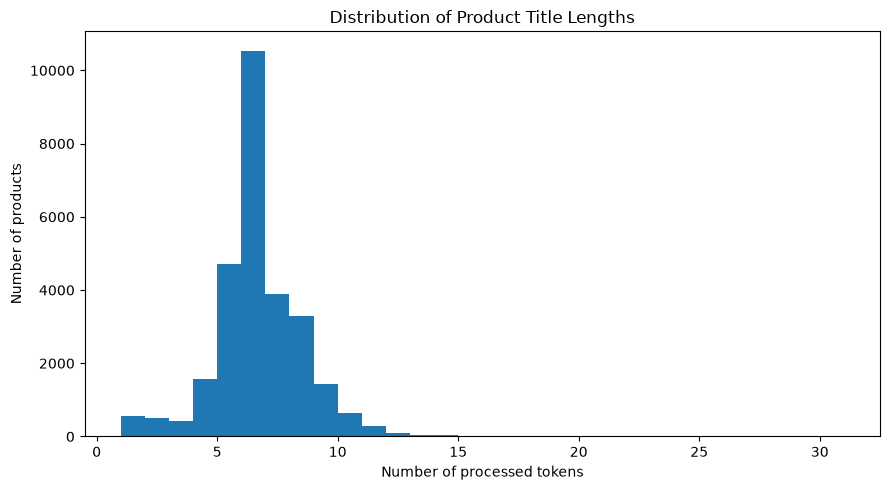

In [43]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["title_length"],
    bins=30,
)

plt.xlabel("Number of processed tokens")
plt.ylabel("Number of products")
plt.title("Distribution of Product Title Lengths")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "title_length_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

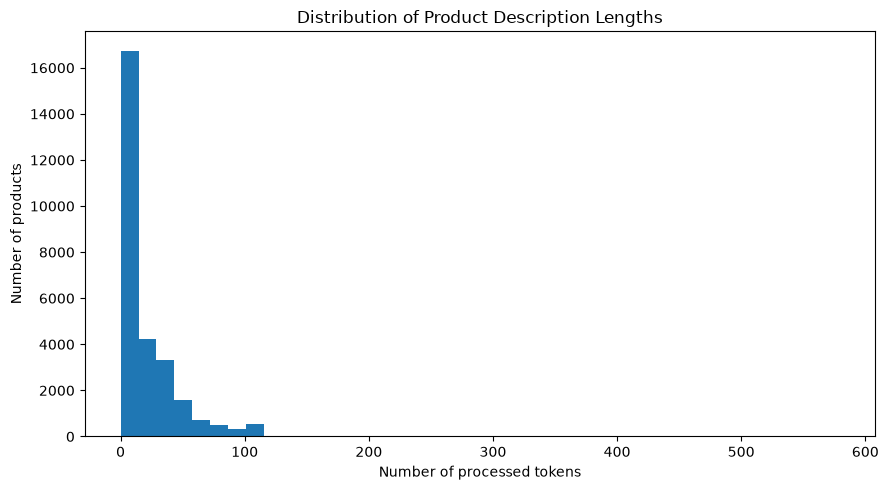

In [44]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["description_length"],
    bins=40,
)

plt.xlabel("Number of processed tokens")
plt.ylabel("Number of products")
plt.title("Distribution of Product Description Lengths")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "description_length_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

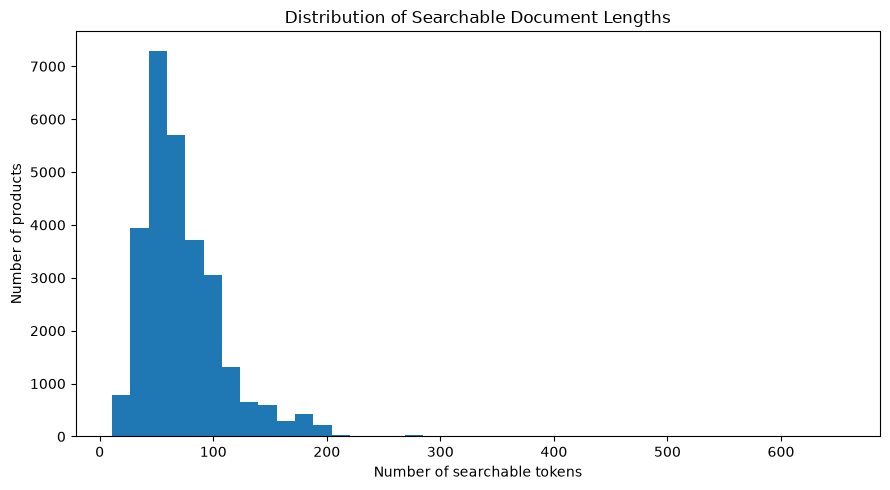

In [45]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["search_document_length"],
    bins=40,
)

plt.xlabel("Number of searchable tokens")
plt.ylabel("Number of products")
plt.title("Distribution of Searchable Document Lengths")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "search_document_length_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [46]:
def sentence_lengths(text):
    """
    Return word counts for approximately detected sentences.

    This function is used only for exploratory analysis and does not affect
    the search-engine preprocessing pipeline.
    """
    if text is None:
        return []

    try:
        if pd.isna(text):
            return []
    except (TypeError, ValueError):
        pass

    text = str(text).strip()

    if not text:
        return []

    sentences = re.split(r"[.!?]+", text)

    lengths = []

    for sentence in sentences:
        words = tokenize_text(sentence)

        if words:
            lengths.append(len(words))

    return lengths

In [47]:
all_sentence_lengths = []

for description in df["description"]:
    all_sentence_lengths.extend(
        sentence_lengths(description)
    )

print(
    "Number of detected sentences:",
    f"{len(all_sentence_lengths):,}",
)

if all_sentence_lengths:
    print(
        "Average sentence length:",
        round(np.mean(all_sentence_lengths), 2),
        "words",
    )

    print(
        "Median sentence length:",
        round(np.median(all_sentence_lengths), 2),
        "words",
    )

Number of detected sentences: 56,498
Average sentence length: 15.17 words
Median sentence length: 14.0 words


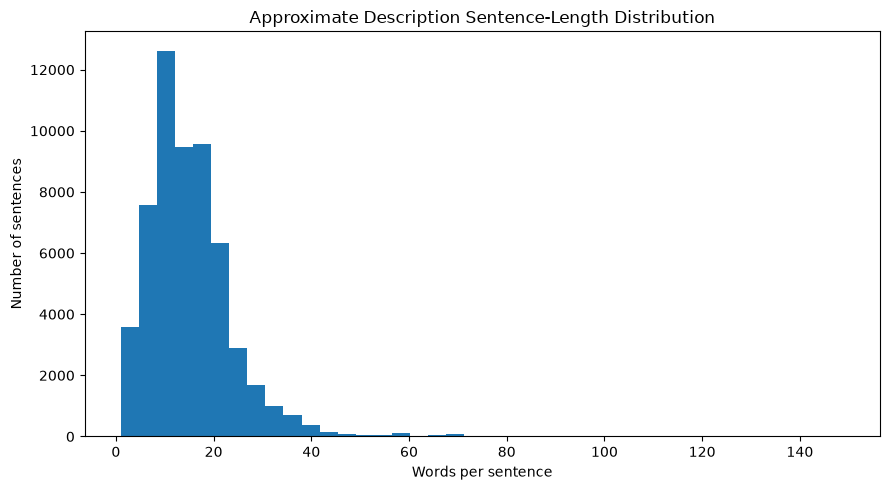

In [48]:
plt.figure(figsize=(9, 5))

plt.hist(
    all_sentence_lengths,
    bins=40,
)

plt.xlabel("Words per sentence")
plt.ylabel("Number of sentences")
plt.title("Approximate Description Sentence-Length Distribution")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "sentence_length_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 3.3 Vocabulary and term-frequency analysis

In [49]:
all_search_tokens = [
    token
    for document_tokens in df["search_tokens"]
    for token in document_tokens
]

term_counts = Counter(all_search_tokens)

vocabulary = set(all_search_tokens)

print(
    "Total processed token occurrences:",
    f"{len(all_search_tokens):,}",
)

print(
    "Vocabulary size:",
    f"{len(vocabulary):,}",
)

Total processed token occurrences: 2,044,182
Vocabulary size: 20,677


In [52]:
top_terms = pd.DataFrame(
    term_counts.most_common(10),
    columns=[
        "term",
        "frequency",
    ],
)

top_terms

,term,frequency
0,fabric,57885
1,neck,57442
2,sleev,51422
3,shirt,50962
4,fit,39764
5,type,38734
6,color,37509
7,cotton,34482
8,wear,31698
9,cloth,31085


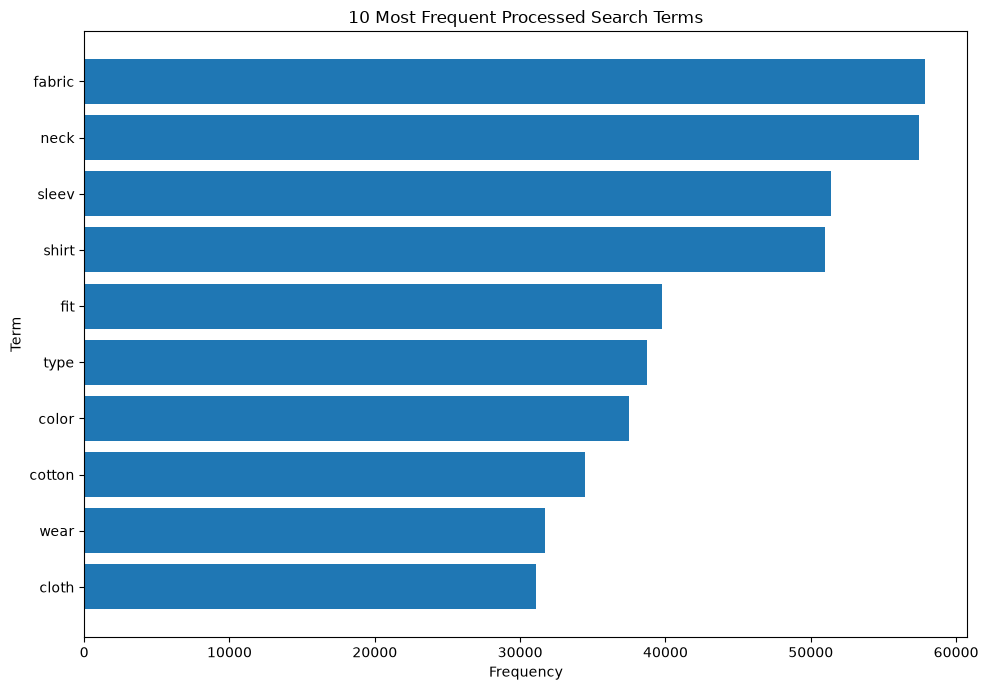

In [54]:
top_10_terms = top_terms.head(10).sort_values(
    "frequency",
    ascending=True,
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_10_terms["term"],
    top_10_terms["frequency"],
)

plt.xlabel("Frequency")
plt.ylabel("Term")
plt.title("10 Most Frequent Processed Search Terms")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "top_search_terms.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [55]:
def preprocess_for_eda(text):
    """
    Create human-readable tokens for EDA visualizations.

    Unlike the retrieval representation, stemming is not performed because
    original words are easier to interpret in plots and word clouds.
    """
    tokens = tokenize_text(text)
    tokens = remove_stopwords(tokens)

    return tokens

In [81]:
df["title_eda_tokens"] = (
    df["title"]
    .apply(preprocess_for_eda)
)

df["description_eda_tokens"] = (
    df["description"]
    .apply(preprocess_for_eda)
)

all_eda_tokens = []

for tokens in df["title_eda_tokens"]:
    all_eda_tokens.extend(tokens)

for tokens in df["description_eda_tokens"]:
    all_eda_tokens.extend(tokens)

eda_term_counts = Counter(all_eda_tokens)

eda_term_counts.most_common(10)

[('shirt', 28358),
 ('women', 17058),
 ('men', 16298),
 ('neck', 14943),
 ('cotton', 11795),
 ('solid', 10558),
 ('round', 10190),
 ('printed', 9717),
 ('fit', 9314),
 ('casual', 8873)]

### 3.4 Word cloud

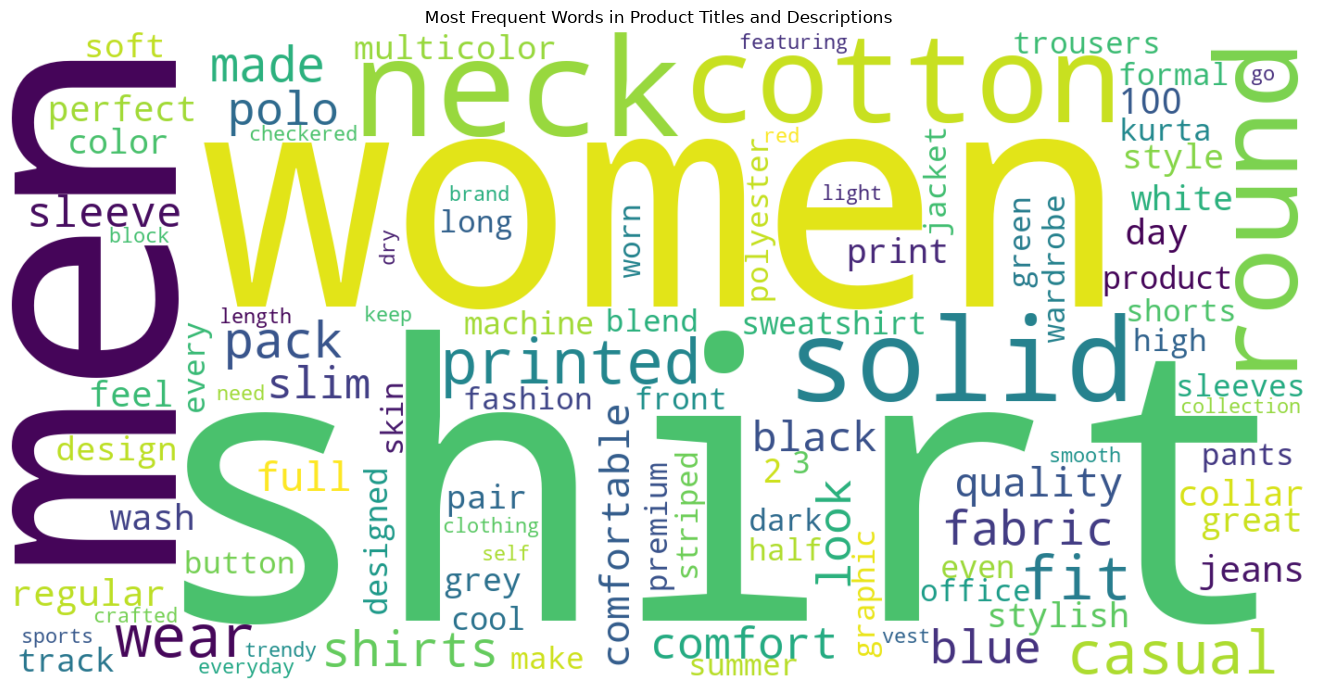

In [57]:
wordcloud_frequencies = dict(
    eda_term_counts.most_common(300)
)

wordcloud = WordCloud(
    width=1400,
    height=700,
    background_color="white",
    max_words=100,
).generate_from_frequencies(
    wordcloud_frequencies
)

plt.figure(figsize=(14, 7))

plt.imshow(
    wordcloud,
    interpolation="bilinear",
)

plt.axis("off")
plt.title("Most Frequent Words in Product Titles and Descriptions")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "wordcloud.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 3.5 Product categories and subcategories

In [82]:
category_counts = (
    df["category"]
    .fillna("Missing")
    .value_counts()
)

category_counts.head(10)

category
Clothing and Accessories    27118
Footwear                      920
Bags, Wallets & Belts          41
Toys                            1
Name: count, dtype: int64

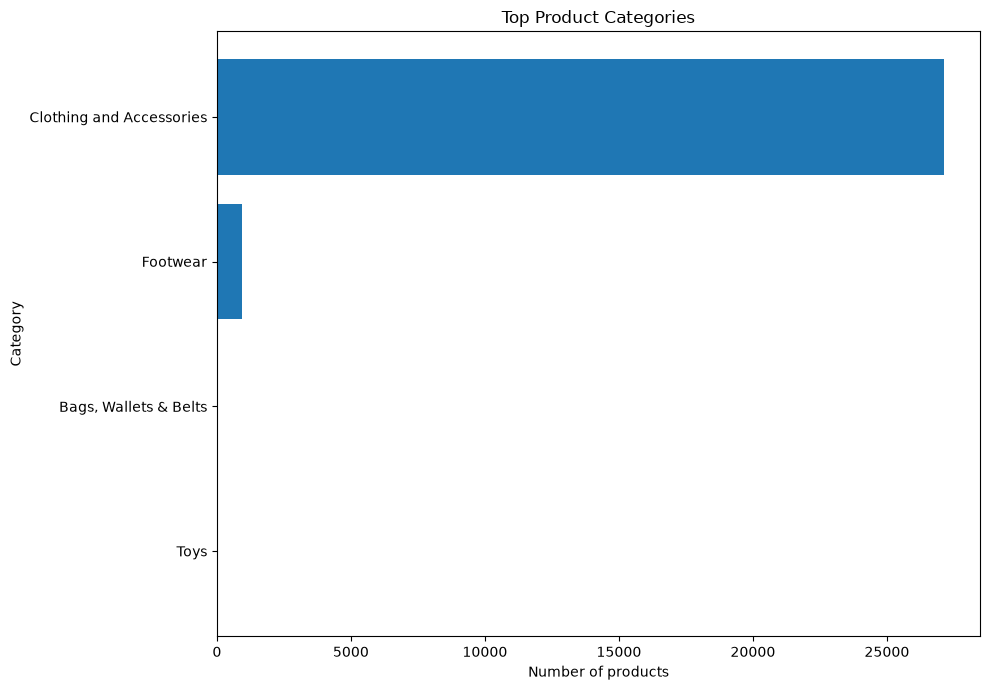

In [83]:
top_categories = (
    category_counts
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_categories.index,
    top_categories.values,
)

plt.xlabel("Number of products")
plt.ylabel("Category")
plt.title("Top Product Categories")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "top_categories.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [84]:
subcategory_counts = (
    df["sub_category"]
    .fillna("Missing")
    .value_counts()
)

subcategory_counts.head(10)

sub_category
Topwear                            15310
Bottomwear                          3666
Winter Wear                         2493
Innerwear and Swimwear              1762
Clothing Accessories                1742
Kurtas, Ethnic Sets and Bottoms     1180
Men's Footwear                       920
Fabrics                              534
Sleepwear                            122
Blazers, Waistcoats and Suits        103
Name: count, dtype: int64

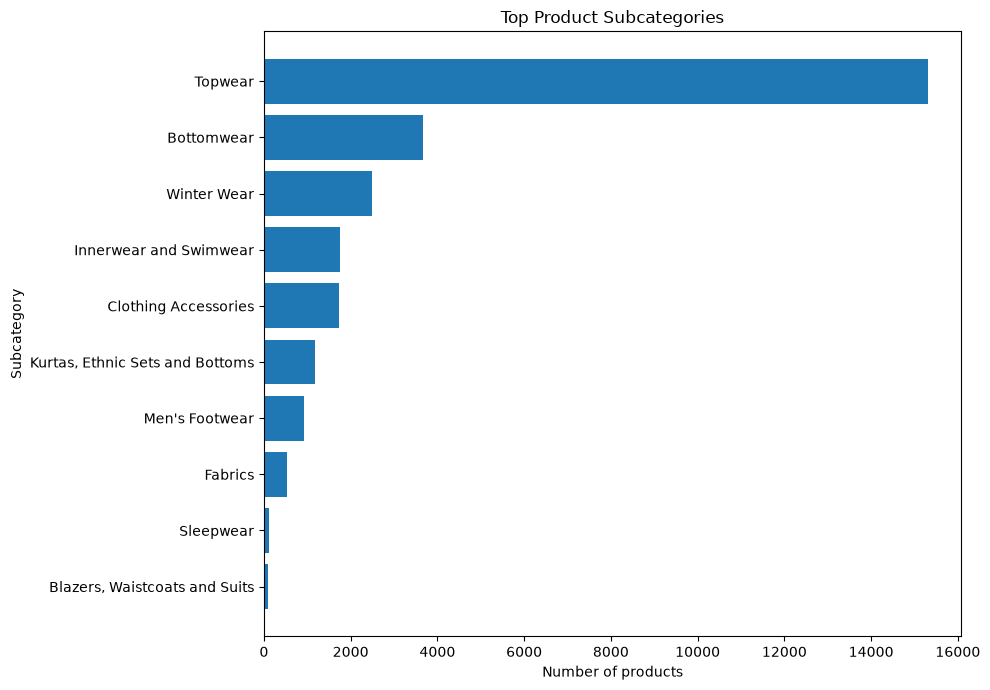

In [85]:
top_subcategories = (
    subcategory_counts
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_subcategories.index,
    top_subcategories.values,
)

plt.xlabel("Number of products")
plt.ylabel("Subcategory")
plt.title("Top Product Subcategories")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "top_subcategories.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 3.6 Brand distribution

In [86]:
brand_counts = (
    df["brand"]
    .fillna("Missing")
    .value_counts()
)

print(
    "Number of unique brands:",
    df["brand"].nunique(dropna=True),
)

brand_counts.head(10)

Number of unique brands: 325


brand
                2009
ECKO Unl         951
Free Authori     860
ARBO             806
REEB             802
Pu               798
True Bl          793
Keo              660
Amp              585
Black Beat       548
Name: count, dtype: int64

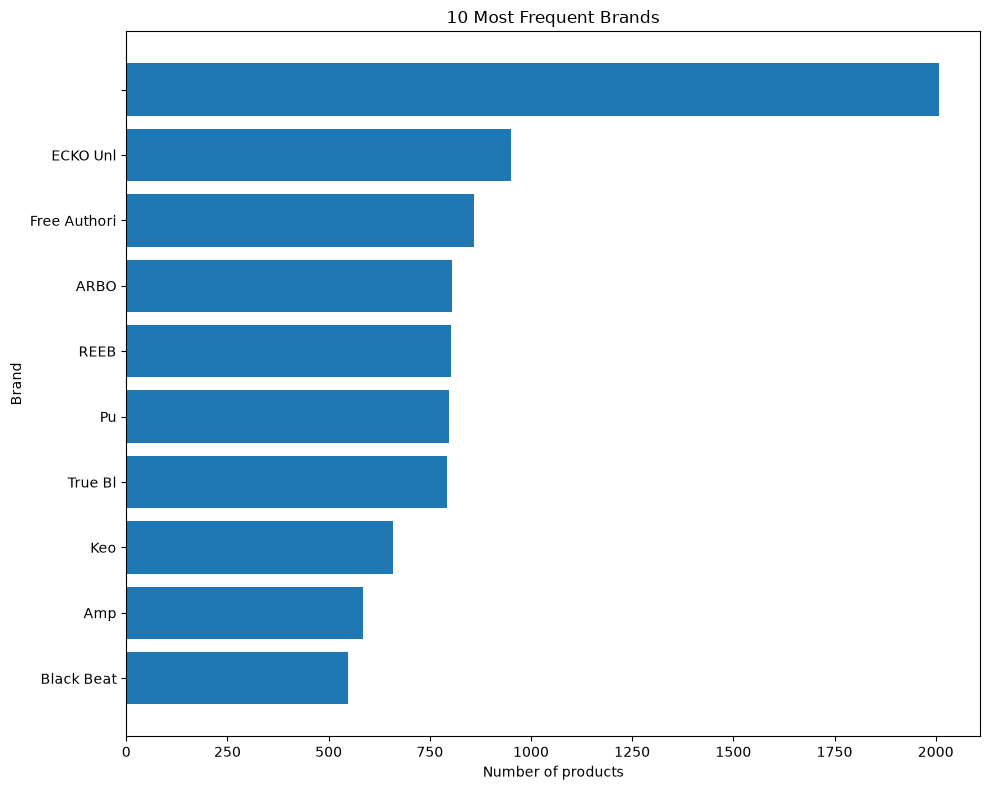

In [87]:
top_brands = (
    brand_counts
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_brands.index,
    top_brands.values,
)

plt.xlabel("Number of products")
plt.ylabel("Brand")
plt.title("10 Most Frequent Brands")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "top_brands.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 3.7 Seller distribution

In [88]:
seller_counts = (
    df["seller"]
    .fillna("Missing")
    .value_counts()
)

print(
    "Number of unique sellers:",
    df["seller"].nunique(dropna=True),
)

seller_counts.head(10)

Number of unique sellers: 535


seller
                         1643
RetailNet                1411
SandSMarketing            887
BioworldMerchandising     842
ARBOR                     783
Keoti                     660
AFFGARMENTS               587
Black Beatle              548
AMALGUS ENTERPRISE        477
Tayab Manch Fashions      436
Name: count, dtype: int64

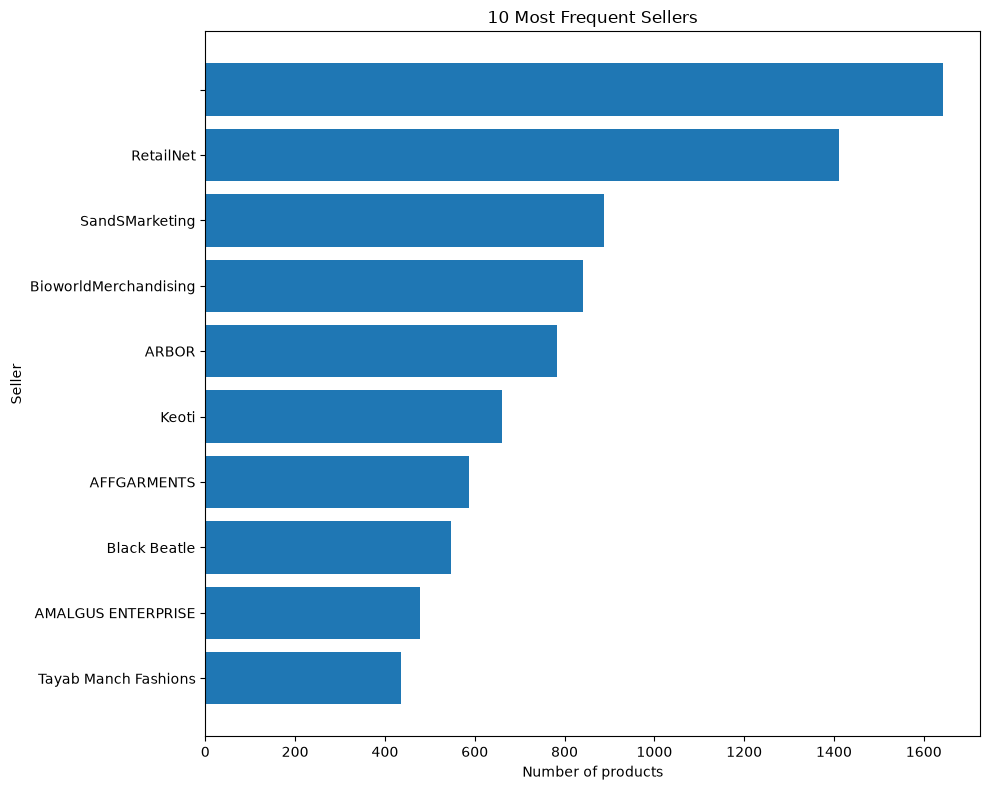

In [89]:
top_sellers = (
    seller_counts
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_sellers.index,
    top_sellers.values,
)

plt.xlabel("Number of products")
plt.ylabel("Seller")
plt.title("10 Most Frequent Sellers")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "top_sellers.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 3.8 Product availability

In [66]:
stock_counts = (
    df["out_of_stock"]
    .value_counts(dropna=False)
)

stock_counts

out_of_stock
False    26436
True      1644
Name: count, dtype: int64

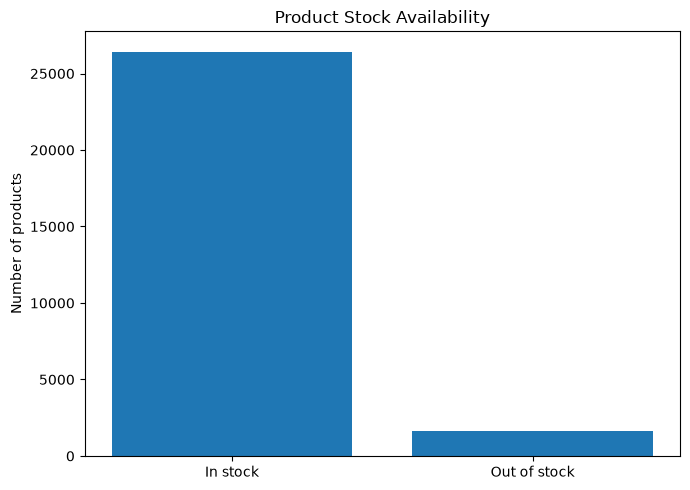

In [67]:
stock_plot = pd.Series({
    "In stock": (~df["out_of_stock"]).sum(),
    "Out of stock": df["out_of_stock"].sum(),
})

plt.figure(figsize=(7, 5))

plt.bar(
    stock_plot.index,
    stock_plot.values,
)

plt.ylabel("Number of products")
plt.title("Product Stock Availability")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "stock_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 3.9 Price analysis

In [68]:
df[
    [
        "selling_price_numeric",
        "actual_price_numeric",
    ]
].describe(
    percentiles=[
        0.25,
        0.5,
        0.75,
        0.9,
        0.95,
        0.99,
    ]
)

,selling_price_numeric,actual_price_numeric
count,28078.000000,27303.000000
mean,705.635088,1455.528110
std,549.681489,939.977456
min,99.000000,150.000000
25%,390.000000,849.000000
50%,545.000000,1199.000000
75%,820.000000,1799.000000
90%,1259.000000,2598.000000
95%,1676.450000,2999.000000
99%,2999.000000,4999.000000


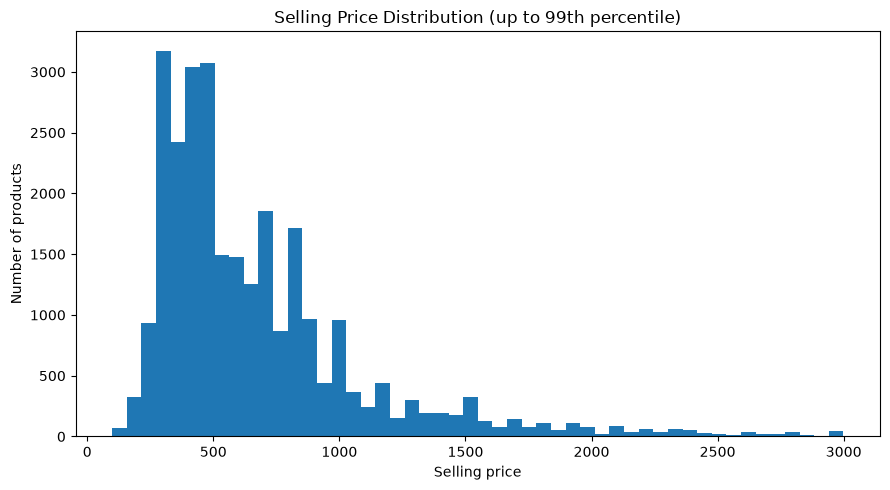

In [69]:
selling_price_99 = (
    df["selling_price_numeric"]
    .quantile(0.99)
)

plt.figure(figsize=(9, 5))

plt.hist(
    df.loc[
        df["selling_price_numeric"] <= selling_price_99,
        "selling_price_numeric",
    ].dropna(),
    bins=50,
)

plt.xlabel("Selling price")
plt.ylabel("Number of products")
plt.title("Selling Price Distribution (up to 99th percentile)")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "selling_price_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 3.10 Discount analysis

In [70]:
df["discount_numeric"].describe()

count    27225.000000
mean        50.256896
std         16.887287
min          1.000000
25%         40.000000
50%         53.000000
75%         63.000000
max         87.000000
Name: discount_numeric, dtype: float64

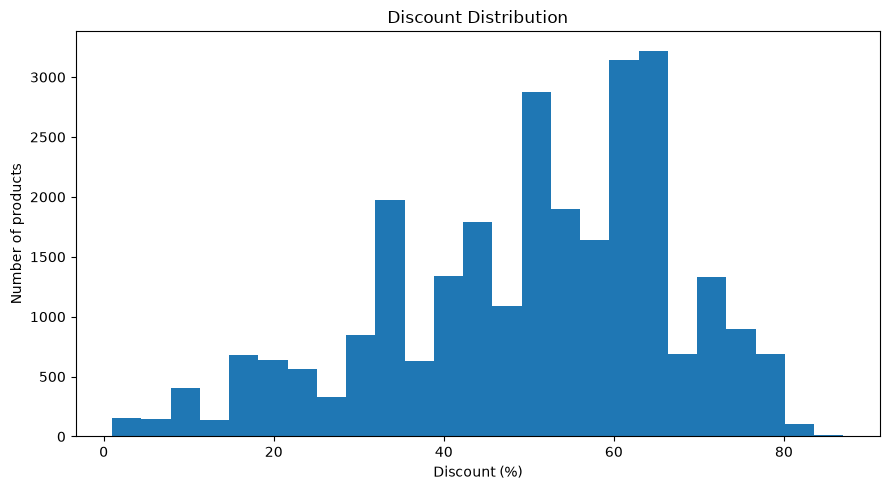

In [71]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["discount_numeric"].dropna(),
    bins=25,
)

plt.xlabel("Discount (%)")
plt.ylabel("Number of products")
plt.title("Discount Distribution")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "discount_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 3.11 Rating analysis

In [72]:
df["average_rating_numeric"].describe()

count    25819.000000
mean         3.627724
std          0.663429
min          1.000000
25%          3.200000
50%          3.800000
75%          4.100000
max          5.000000
Name: average_rating_numeric, dtype: float64

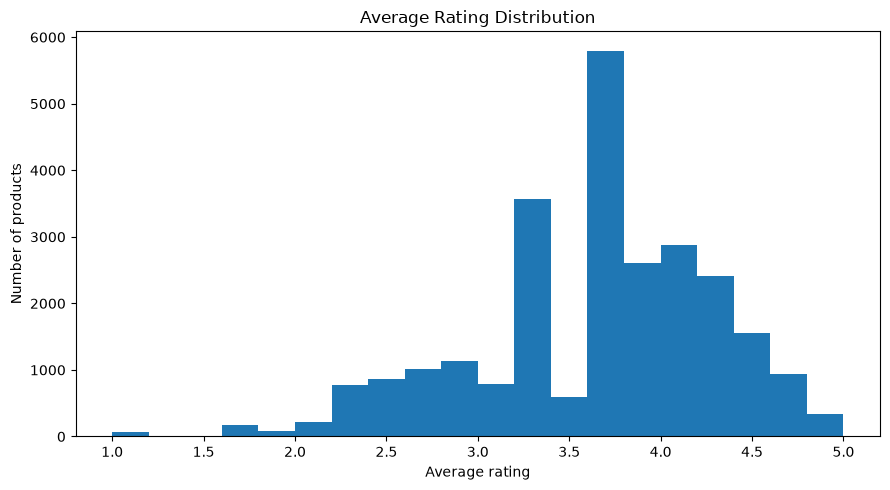

In [73]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["average_rating_numeric"].dropna(),
    bins=20,
)

plt.xlabel("Average rating")
plt.ylabel("Number of products")
plt.title("Average Rating Distribution")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "rating_distribution.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

### 3.12 Example product rankings

In [74]:
top_rated = (
    df[
        [
            "pid",
            "title",
            "brand",
            "average_rating_numeric",
            "selling_price_numeric",
        ]
    ]
    .dropna(
        subset=["average_rating_numeric"]
    )
    .sort_values(
        [
            "average_rating_numeric",
            "selling_price_numeric",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .head(10)
)

top_rated

,pid,title,brand,average_rating_numeric,selling_price_numeric
13251,VESFSJ92YXMAJZFX,Sheny Women Vest,,5.0,184.0
9482,TSHFJHFFQHQBNVSV,Solid Women Round Neck Red T-Shirt,FancyW,5.0,215.0
4683,TSHFVUXHTE5KH7RH,Solid Men Polo Neck Dark Blue T-Shirt,Shoef,5.0,246.0
417,BXRFGYUGJCWWZ7UG,Printed Men Boxer (Pack of 1),SayItLo,5.0,249.0
443,BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),SayItLo,5.0,249.0
3113,TSHFT9ZTPYVXTJY7,Printed Women Round Neck Yellow T-Shirt,REF,5.0,259.0
17993,TSHFNJ9ZEUZG3CPU,Printed Women Round Neck Multicolor T-Shirt,yellowvib,5.0,275.0
1160,TSHFVEHX5PURAVHT,Color Block Men Round Neck Multicolor T-Shirt,Clo,5.0,284.0
18503,TSHFTT2JATXKUHEV,Solid Women Round Neck Black T-Shirt,PixF,5.0,288.0
18543,TSHFSPXRXEFVFTXG,Solid Women Round Neck Dark Blue T-Shirt,PixF,5.0,288.0


In [75]:
most_expensive = (
    df[
        [
            "pid",
            "title",
            "brand",
            "selling_price_numeric",
            "average_rating_numeric",
        ]
    ]
    .dropna(
        subset=["selling_price_numeric"]
    )
    .sort_values(
        "selling_price_numeric",
        ascending=False,
    )
    .head(10)
)

most_expensive

,pid,title,brand,selling_price_numeric,average_rating_numeric
2067,TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,REEB,7999.0,2.7
11010,BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sleeve Blazer (Grey),True Bl,7998.0,2.6
25815,JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,Pu,7799.0,3.7
26089,SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,Pu,7799.0,4.5
6895,JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,G,7794.0,4.2
11008,BZRFVDGUJHTQHDAX,Self Design Single Breasted Party Women Full Sleeve Blazer (Blue),True Bl,6998.0,2.6
6898,JEAF8S4GE8PKH7H3,Regular Fit Men Dark Blue Cotton Blend Trousers,G,6925.0,4.5
6901,JEAF65G3MZYG3BQM,Maxx Regular Men Black Jeans,G,6692.0,3.8
25423,JCKFQF5K72AT2JDC,Full Sleeve Solid Women Casual Jacket,Pu,6499.0,3.7
6855,JEAFEN3WGHH3ZEFY,Skinny Men Blue Jeans,G,6493.0,NaN


In [76]:
highest_discount = (
    df[
        [
            "pid",
            "title",
            "brand",
            "discount_numeric",
            "selling_price_numeric",
            "actual_price_numeric",
        ]
    ]
    .dropna(
        subset=["discount_numeric"]
    )
    .sort_values(
        "discount_numeric",
        ascending=False,
    )
    .head(10)
)

highest_discount

,pid,title,brand,discount_numeric,selling_price_numeric,actual_price_numeric
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,87.0,128.0,998.0
902,TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,Jack Roy,86.0,136.0,999.0
903,TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,Jack Roy,86.0,136.0,999.0
18249,TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pack of 2),yellowvib,85.0,449.0,2999.0
9813,CAPE9YWMURE4FKAJ,Solid Balclava Cap,Gracew,84.0,228.0,1499.0
91,CTPFVZTBN4GRZKXH,nu-Lite Satin Tie & Cufflink (Red),,84.0,499.0,3299.0
18093,TSHFGFNBYVKZBQ2M,Printed Men Collared Neck Multicolor T-Shirt,yellowvib,84.0,230.0,1500.0
520,TSHEYQ73AFZZ4QHX,"Printed Women Round or Crew Black, Grey T-Shirt",Fairdea,84.0,201.0,1299.0
18016,TSHFHQNCHJJUQYVQ,Printed Women Round Neck Blue T-Shirt,yellowvib,84.0,280.0,1800.0
18017,TSHFKHRYJYMEMZHK,Printed Men Mandarin Collar Blue T-Shirt,yellowvib,84.0,282.0,1800.0


### 3.13 Relationship between price and discount

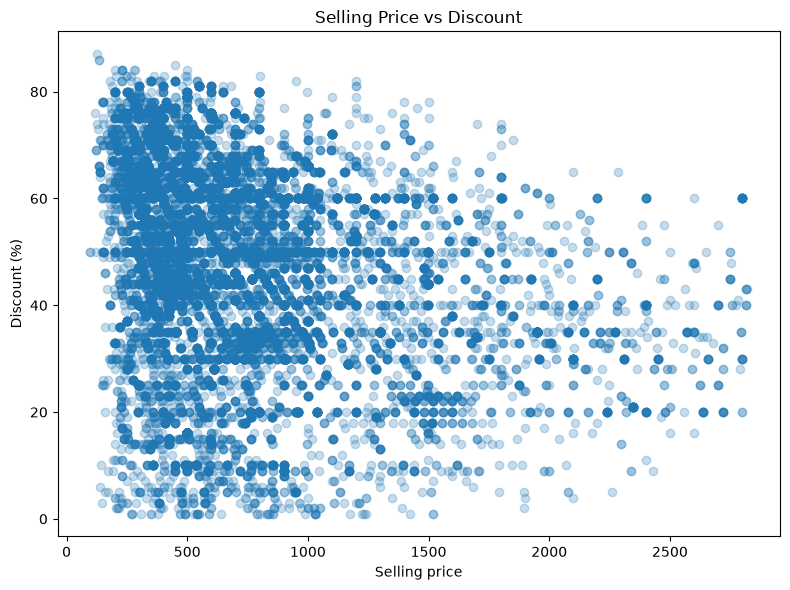

In [77]:
price_discount = df[
    [
        "selling_price_numeric",
        "discount_numeric",
    ]
].dropna()

price_limit = (
    price_discount["selling_price_numeric"]
    .quantile(0.99)
)

price_discount_plot = price_discount[
    price_discount["selling_price_numeric"]
    <= price_limit
]

plt.figure(figsize=(8, 6))

plt.scatter(
    price_discount_plot["selling_price_numeric"],
    price_discount_plot["discount_numeric"],
    alpha=0.25,
)

plt.xlabel("Selling price")
plt.ylabel("Discount (%)")
plt.title("Selling Price vs Discount")

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "price_vs_discount.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [78]:
price_discount_correlation = (
    price_discount[
        [
            "selling_price_numeric",
            "discount_numeric",
        ]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    "Pearson correlation between selling price and discount:",
    round(price_discount_correlation, 3),
)

Pearson correlation between selling price and discount: -0.295


### 3.14 Generated figures overview

In [90]:
generated_figures = sorted(
    FIGURES_PATH.glob("*.png")
)

print(
    f"Generated {len(generated_figures)} figures:"
)

for figure in generated_figures:
    print("-", figure.name)

Generated 15 figures:
- description_length_distribution.png
- discount_distribution.png
- price_vs_discount.png
- rating_distribution.png
- search_document_length_distribution.png
- selling_price_distribution.png
- sentence_length_distribution.png
- stock_distribution.png
- title_length_distribution.png
- top_brands.png
- top_categories.png
- top_search_terms.png
- top_sellers.png
- top_subcategories.png
- wordcloud.png
